In [1]:
import os
os.chdir("D:/tmp_workplace/dynamic_structure/250324/all_rRNA_prediction/test/river_internal_test/without_structure_feature_detection")
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def find_stems(file):
    length = 5070

    raw_matrix = np.zeros((length,length))

    with open(file,"r")as f:
        for line in f:
            if "chrom" in line:
                continue
            else:
                sub = line.strip().split()
                left = int(sub[1])
                right = int(sub[4])
                if (left <= right):
                    raw_matrix[int(left),int(right)] = 1

    matrix = np.triu(raw_matrix, k=1)
    n = matrix.shape[0]
    
    unit_loc = {}
    unit_id = 0
    m = 0

    for k in range(1, 2 * n - 1):
        row_start = max(0, k - (n - 1))
        row_end = min((k + 1) // 2, n)
        
        if row_end <= row_start:
            continue
        
        rows = np.arange(row_start, row_end)
        cols = k - rows
        values = matrix[rows, cols]
        
        positive = values > 0
        
        if not positive.any():
            continue
        
        diff = np.diff(positive.astype(int))
        starts = np.where(diff == 1)[0] + 1
        ends = np.where(diff == -1)[0] + 1
        
        if positive[0]:
            starts = np.concatenate(([0], starts))
        if positive[-1]:
            ends = np.concatenate((ends, [len(positive)]))
        
        for start, end in zip(starts, ends):
            seg_len = end - start
            if seg_len >= 2:
                m += 1
                #out.write(str(seg_len)+"\n")
                #unit_id += 1
                #seg_rows = rows[start:end]
                #seg_cols = cols[start:end]
                #pixel_list = [f"{r}_{c}" for r, c in zip(seg_rows, seg_cols)]
                #unit_loc[f's{unit_id}'] = pixel_list
        
    print(m)

In [3]:
find_stems("wd_structure1.bedpe")

261


In [4]:
find_stems("raw_structure1.bedpe")

197


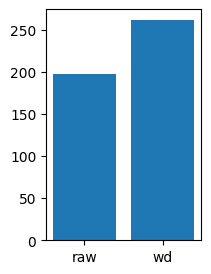

In [5]:
fig, ax = plt.subplots(figsize=(2,3))

ax.bar(["raw","wd"], [197,261])
plt.savefig("const_stem_count.pdf",format="pdf")